## 7.1 Import & Utilitas

In [39]:
# Import
import numpy as np
import matplotlib.pyplot as plt

# Utilitas
def plot_error(h, errors_dict, title):
    colors = {
        "Forward": "blue",
        "Backward": "red",
        "Central": "green",
        "Richardson": "purple"
    }
    
    for label, err in errors_dict.items():
        plt.loglog(h, err, label=label, color=colors.get(label, None))
    
    plt.xlabel('h')
    plt.ylabel('Error')
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()

# galat absolut
def error_abs(approx, exact):
    return abs(approx - exact)


# Error untuk turunan pertama
def error1(f, df, method, x0, h_values):
    errors = []
    for h in h_values:
        approx = method(f, x0, h)
        exact = df(x0)
        errors.append(error_abs(approx, exact))
    return errors

# Error untuk turunan kedua
def error2(f, d2f, method, x0, h_values):
    errors = []
    for h in h_values:
        approx = method(f, x0, h)
        exact = d2f(x0)
        errors.append(error_abs(approx, exact))
    return errors

# Error untuk richardson
def compute_error_richardson(f, df, method,richardson, x0, h_values, p):
    error_base = []
    error_rich = []
    
    for h in h_values:
        exact = df(x0)
        
        # metode biasa
        D_h = method(f, x0, h)
        error_base.append(error_abs(D_h, exact))
        
        # metode dengan h/2
        D_h2 = method(f, x0, h/2)
        
        # Richardson
        D_rich = richardson(D_h, D_h2, p)
        error_rich.append(error_abs(D_rich, exact))
    
    return error_base, error_rich



## 7.2 Skema Beda Hingga — Turunan Pertama

Turunan pertama suatu fungsi dapat didekati menggunakan pendekatan beda hingga yang berasal dari ekspansi Taylor.

Tiga metode utama:

1. Forward Difference
𝑓
′
(
𝑥
)
≈
𝑓
(
𝑥
+
ℎ
)
−
𝑓
(
𝑥
)
ℎ
f
′
(x)≈
h
f(x+h)−f(x)
	​

Menggunakan titik di depan (x + h)
Orde galat: 
𝑂
(
ℎ
)
O(h)
Sederhana, tetapi kurang akurat

In [40]:
# Forward Difference
def forward_diff(f, x, h):
    return (f(x + h) - f(x)) / h

# Backward Difference
def backward_diff(f, x, h):
    return (f(x) - f(x - h)) / h

# Central Difference
def central_diff(f, x, h):
    return (f(x + h) - f(x - h)) / (2*h)

In [41]:
# Forward Difference (3 titik)
def forward_diff_2(f, x, h):
    return (f(x) - 2*f(x + h) + f(x + 2*h)) / (h**2)

# Backward Difference (3 titik)
def backward_diff_2(f, x, h):
    return (f(x) - 2*f(x - h) + f(x - 2*h)) / (h**2)

# Central Difference (3 titik)
def central_diff_2(f, x, h):
    return (f(x + h) - 2*f(x) + f(x - h)) / (h**2)


In [42]:
def richardson(D_h, D_h2, p):
    return D_h2 + (D_h2 - D_h) / (2**p - 1)

In [43]:
# f1(x) = e^x
def f1(x): return np.exp(x)
def df1(x): return np.exp(x)
def d2f1(x): return np.exp(x)

# f2(x) = sin(x)
def f2(x): return np.sin(x)
def df2(x): return np.cos(x)
def d2f2(x): return -np.sin(x)

# f3(x) = ln(1+x)
def f3(x): return np.log(1 + x)
def df3(x): return 1/(1 + x)
def d2f3(x): return -1/(1 + x)**2


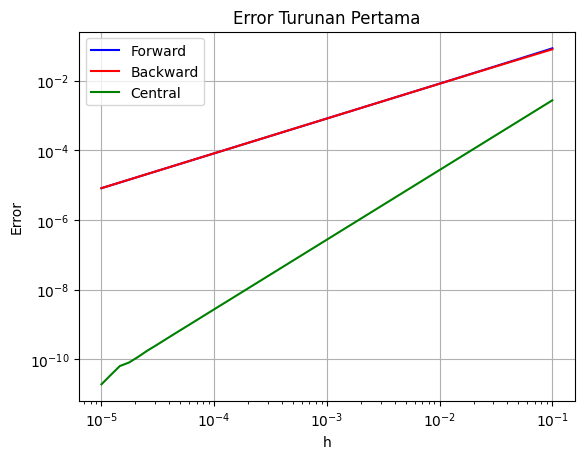

In [ ]:
x0 = 0.5
h_values = np.logspace(0.2, 50)

err_f = error1(f1, df1, forward_diff, x0, h_values)
err_b = error1(f1, df1, backward_diff, x0, h_values)
err_c = error1(f1, df1, central_diff, x0, h_values)

plot_error(h_values, {
    "Forward": err_f,
    "Backward": err_b,
    "Central": err_c
}, "Error Turunan Pertama")

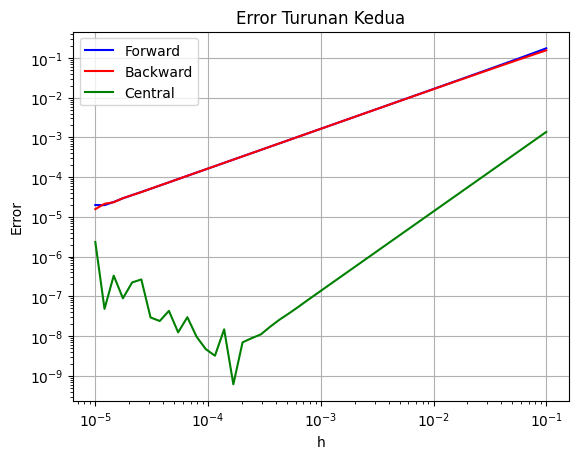

In [45]:
err_f2 = error2(f1, df1, forward_diff_2, x0, h_values)
err_b2 = error2(f1, df1, backward_diff_2, x0, h_values)
err_c2 = error2(f1, df1, central_diff_2, x0, h_values)

plot_error(h_values, {
    "Forward": err_f2,
    "Backward": err_b2,
    "Central": err_c2
}, "Error Turunan Kedua")

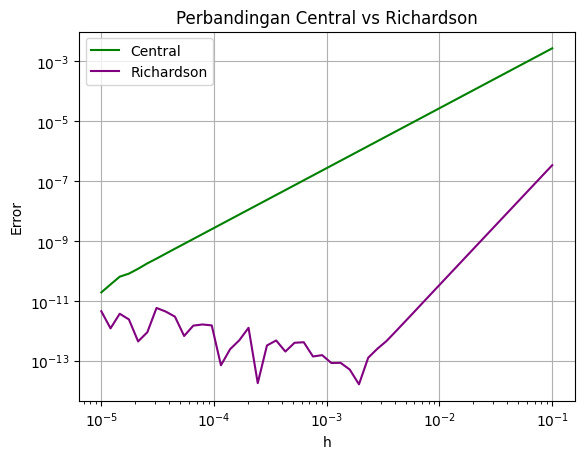

In [46]:
err_central, err_rich = compute_error_richardson(
    f1, df1, central_diff, richardson, x0, h_values, p=2
)

plot_error(h_values, {
    "Central": err_central,
    "Richardson": err_rich
}, "Perbandingan Central vs Richardson")

